# Boosting and Stacking Exercises
Exerciții de stimulare și stivuire

![Boosting.png](Assets/Boosting.png)

# Obiectivele învățării

- Explicarea modului în care algoritmul boosting ajută la reducerea varianței și a prejudecăților.


## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones] (https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construită pe baza înregistrărilor participanților la studiu care efectuează activități de viață zilnică (ADL) în timp ce poartă un smartphone cu senzori inerțiali încorporați. Obiectivul este de a clasifica activitățile într-una dintre cele șase activități (mersul pe jos, mersul pe scări, mersul pe scări, șezutul, statul în picioare și întinderea) efectuate.

Pentru fiecare înregistrare din setul de date se furnizează: 

- accelerația triaxială de la accelerometru (accelerația totală) și accelerația corpului estimată. 
- Viteza unghiulară triaxială de la giroscop. 
- Un vector de 561 de caracteristici cu variabile în domeniul timpului și al frecvenței. 
- Eticheta activității sale. 

Mai multe informații despre caracteristici sunt disponibile pe site-ul de mai sus.

In [2]:
from __future__ import print_function

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

import matplotlib.pyplot as plt


## Întrebare 1

* Importați datele din fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv` și examinați forma și tipurile de date. Pentru tipurile de date, vor fi prea multe pentru a lista fiecare coloană separat. Mai degrabă, agregați tipurile după număr.
* Determinați dacă coloanele float trebuie să fie scalate.

In [3]:
import pandas as pd
import numpy as np

data = pd.read_csv('Human_Activity_Recognition_Using_Smartphones_Data.csv')

print('Forma setului de date:', data.shape)
print('Tipuri de date agregate:')
print(data.dtypes.value_counts())
print('Valori minime și maxime pentru coloanele numerice:')
print(data.select_dtypes(include=[np.number]).agg(['min', 'max']).T.head())
print('Intervalul global al coloanelor numerice:')
print(data.select_dtypes(include=[np.number]).agg(['min', 'max']).to_numpy().min(),
      data.select_dtypes(include=[np.number]).agg(['min', 'max']).to_numpy().max())

Forma setului de date: (10299, 562)
Tipuri de date agregate:
float64    561
str          1
Name: count, dtype: int64
Valori minime și maxime pentru coloanele numerice:
                   min  max
tBodyAcc-mean()-X -1.0  1.0
tBodyAcc-mean()-Y -1.0  1.0
tBodyAcc-mean()-Z -1.0  1.0
tBodyAcc-std()-X  -1.0  1.0
tBodyAcc-std()-Y  -1.0  1.0
Intervalul global al coloanelor numerice:
-1.0 1.0


Datele au destul de multe coloane predictoare.

Și toate sunt valori float. Singura valoare care nu este float este coloana categoriilor, care este cea care este prezisă.

Valoarea minimă și maximă pentru coloanele float este -1.0 și, respectiv, 1.0. Cu toate acestea, scalarea nu este niciodată necesară pentru metodele bazate pe arbori.

## Întrebare 2

* Codificați activitățile în numere întregi.
* Împărțiți datele în seturi de date de instruire și de testare. Decideți dacă datele vor fi stratificate sau nu în timpul împărțirii tren/test.

**NOTA**: Urmează să creăm seturi de instruire și de testare din `data`. Pe aceste seturi de date, vom rula căutări de tip grilă pe mai multe opțiuni de parametri. Acest lucru poate dura ceva timp. Pentru a scurta timpul de căutare în grilă, nu ezitați să reduceți eșantionarea `date` și să creați `X_train, X_test, y_train, y_test` din setul de date redus la eșantionare.

Împărțiți acum datele în seturi de date de instruire și de testare. O împărțire stratificată nu a fost utilizată aici. Dacă există probleme cu oricare dintre parametrii de eroare pe setul de testare, poate fi o idee bună să începeți ajustarea modelului folosind o împărțire stratificată. Totuși, Boosting este un model destul de puternic, așa că s-ar putea să nu fie necesar în acest caz.

In [4]:
data = data.sample(frac=0.10, random_state=42).reset_index(drop=True)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data['Activity'])
X = data.drop(columns=['Activity'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Clase:', label_encoder.classes_)
print('Dimensiuni:', X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Clase: ['LAYING' 'SITTING' 'STANDING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']
Dimensiuni: (824, 561) (206, 561) (824,) (206,)


## Întrebare 3

* Potriviți modele de arbori gradient boosted cu toți parametrii setați la valorile implicite pentru următoarele numere de arbori (`n_estimatori = [25, 50, 100, 200, 400]`) și evaluați precizia pe datele de test pentru fiecare dintre aceste modele. 
* Reprezentați grafic acuratețea în funcție de numărul de estimatori.

**Nota:** Executarea acestei întrebări poate dura ceva timp, în funcție de cât de multe valori diferite sunt potrivite pentru estimatori. Setarea `max_features=4` în clasificatorul gradient boosting va crește rata de convergență.

De asemenea, acest lucru este similar cu întrebarea 3 din săptămâna 9, cu excepția faptului că nu există o eroare în afara sacului pentru modelele boosted. Iar setarea `warm_flag=True` are o eroare în modelul gradient boosted, deci nu o folosiți. Creați pur și simplu modelul în interiorul buclei `for` și setați numărul de estimatori în acest moment. Acest lucru va face ca ajustarea să dureze puțin mai mult. În plus, ajustarea modelelor boosting tinde să dureze mai mult decât cea a modelelor bagged, deoarece cioturile de decizie trebuie ajustate succesiv.

{25: 0.8932038834951457, 50: 0.9368932038834952, 100: 0.9514563106796117, 200: 0.941747572815534, 400: 0.9320388349514563}


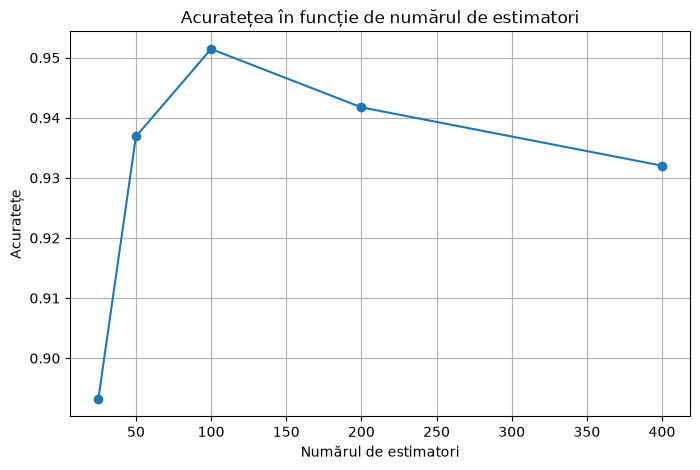

In [5]:
n_estimators = [25, 50, 100, 200, 400]
accuracies = []
gradient_boosting_models = {}

for n in n_estimators:
    model = GradientBoostingClassifier(n_estimators=n, max_features=4, random_state=42)
    model.fit(X_train, y_train)
    gradient_boosting_models[n] = model
    predictions = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, predictions))

print(dict(zip(n_estimators, accuracies)))
plt.figure(figsize=(8, 5))
plt.plot(n_estimators, accuracies, marker='o')
plt.xlabel('Numărul de estimatori')
plt.ylabel('Acuratețe')
plt.title('Acuratețea în funcție de numărul de estimatori')
plt.grid(True)
plt.show()

## Întrebarea 4

* Utilizând o căutare în grilă cu validare încrucișată, potriviți un nou clasificator gradient boosted cu o listă de estimatori, similar cu întrebarea 3. De asemenea, luați în considerare varierea ratelor de învățare (0,1, 0,01, 0,001 etc.), a valorii subeșantionării (1,0 sau 0,5) și a numărului maxim de caracteristici (1, 2 etc.).
* Examinați parametrii modelului cel mai bine adaptat.
* Calculați parametrii de eroare relevanți pentru acest model și examinați matricea de confuzie.

**Notă:** această întrebare poate dura ceva timp pentru a fi executată, în funcție de câte caracteristici sunt asociate cu căutarea în grilă. Se recomandă să începeți cu doar câteva pentru a vă asigura că totul funcționează corect și apoi să adăugați mai multe caracteristici. Setarea `max_features=4` în clasificatorul gradient boosting va crește rata de convergență.

Cei mai buni parametri: {'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 100, 'subsample': 1.0}
Acuratețe validare încrucișată: 0.9551028533510285
Acuratețe test: 0.9514563106796117
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00        37
           SITTING       1.00      0.95      0.97        41
          STANDING       0.93      1.00      0.96        27
           WALKING       0.93      0.97      0.95        40
WALKING_DOWNSTAIRS       0.92      0.89      0.90        37
  WALKING_UPSTAIRS       0.91      0.88      0.89        24

          accuracy                           0.95       206
         macro avg       0.95      0.95      0.95       206
      weighted avg       0.95      0.95      0.95       206



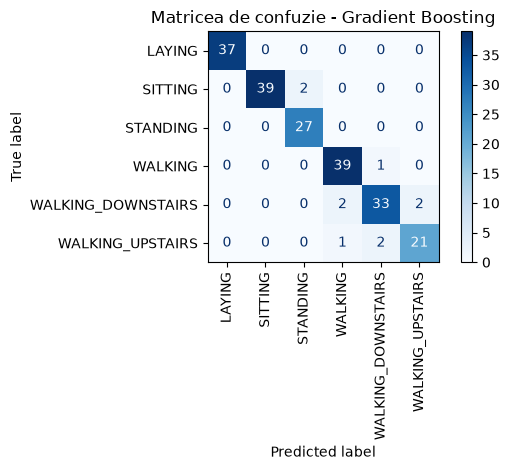

In [6]:
param_grid_gb = {
    'n_estimators': [50, 100],
    'learning_rate': [0.1],
    'subsample': [1.0, 0.5],
    'max_features': [4]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid=param_grid_gb,
    cv=3,
    scoring='accuracy',
    n_jobs=1
)
gb_grid.fit(X_train, y_train)
best_gb = gb_grid.best_estimator_
gb_predictions = best_gb.predict(X_test)

print('Cei mai buni parametri:', gb_grid.best_params_)
print('Acuratețe validare încrucișată:', gb_grid.best_score_)
print('Acuratețe test:', accuracy_score(y_test, gb_predictions))
print(classification_report(y_test, gb_predictions, target_names=label_encoder.classes_, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap='Blues',
    values_format='d',
    xticks_rotation='vertical'
)
plt.title('Matricea de confuzie - Gradient Boosting')
plt.tight_layout()
plt.show()


**Metrica erorilor.** Raportul de clasificare este deosebit de convenabil pentru cazurile cu mai multe clase.

**Matricea de confuzie.** Rețineți că modelul gradient boosted are o mică problemă în a distinge între clasele de activitate 1 și 2.

## Întrebarea 5

* Creați un model AdaBoost și potriviți-l folosind grid search, la fel ca la întrebarea 4. Încercați o gamă de estimatori între 100 și 200.
* Comparați erorile de la AdaBoost cu cele de la GradientBoostedClassifier.

**NOTĂ:** Setarea `max_features=4` în clasificatorul arbore de decizie utilizat ca clasificator de bază pentru AdaBoost va crește rata de convergență.

Cei mai buni parametri AdaBoost: {'learning_rate': 0.5, 'n_estimators': 100}
Acuratețe validare încrucișată AdaBoost: 0.6917319177173192
Acuratețe test AdaBoost: 0.6699029126213593
                    precision    recall  f1-score   support

            LAYING       0.85      0.59      0.70        37
           SITTING       0.59      0.73      0.65        41
          STANDING       0.54      0.56      0.55        27
           WALKING       0.80      0.70      0.75        40
WALKING_DOWNSTAIRS       0.76      0.76      0.76        37
  WALKING_UPSTAIRS       0.52      0.62      0.57        24

          accuracy                           0.67       206
         macro avg       0.67      0.66      0.66       206
      weighted avg       0.69      0.67      0.67       206

Acuratețe Gradient Boosting: 0.9514563106796117


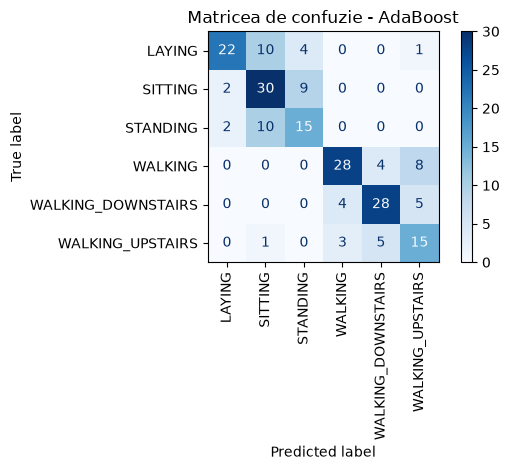

In [7]:
ada_base = DecisionTreeClassifier(max_features=4, random_state=42)
ada_grid = GridSearchCV(
    AdaBoostClassifier(estimator=ada_base, random_state=42),
    param_grid={
        'n_estimators': [100, 200],
        'learning_rate': [0.5, 1.0]
    },
    cv=3,
    scoring='accuracy',
    n_jobs=1
)
ada_grid.fit(X_train, y_train)
best_ada = ada_grid.best_estimator_
ada_predictions = best_ada.predict(X_test)

print('Cei mai buni parametri AdaBoost:', ada_grid.best_params_)
print('Acuratețe validare încrucișată AdaBoost:', ada_grid.best_score_)
print('Acuratețe test AdaBoost:', accuracy_score(y_test, ada_predictions))
print(classification_report(y_test, ada_predictions, target_names=label_encoder.classes_, zero_division=0))
print('Acuratețe Gradient Boosting:', accuracy_score(y_test, gb_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    ada_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap='Blues',
    values_format='d',
    xticks_rotation='vertical'
)
plt.title('Matricea de confuzie - AdaBoost')
plt.tight_layout()
plt.show()


Cel mai potrivit model.

**Parametrii de eroare.** Observați că problemele cu clasele 1 și 2 par să fi devenit mai problematice și includ acum clasa 0. De asemenea, observați alte probleme pentru clasele 3 - 5. AdaBoost este foarte sensibil la valorile aberante, deci aceasta ar putea fi problema aici.

## Întrebare 6

* Adaptați un model de regresie logistică cu regularizare. Acesta poate fi o replică a unui model care a funcționat bine în exercițiile din săptămâna 4.
* Folosind `VotingClassifier`, ajustați modelul de regresie logistică împreună cu modelul GratientBoostedClassifier sau AdaBoost (sau ambele) de la întrebările 4 și 5.
* Determinați eroarea ca mai înainte și comparați rezultatele cu modelul (modelele) corespunzător(e) cu amplificare prin gradient.
* Reprezentați matricea de confuzie pentru cel mai bun model creat în acest set de exerciții.

Acuratețe regresie logistică: 0.9660194174757282
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00        37
           SITTING       0.95      0.93      0.94        41
          STANDING       0.89      0.93      0.91        27
           WALKING       0.98      1.00      0.99        40
WALKING_DOWNSTAIRS       0.97      1.00      0.99        37
  WALKING_UPSTAIRS       1.00      0.92      0.96        24

          accuracy                           0.97       206
         macro avg       0.97      0.96      0.96       206
      weighted avg       0.97      0.97      0.97       206



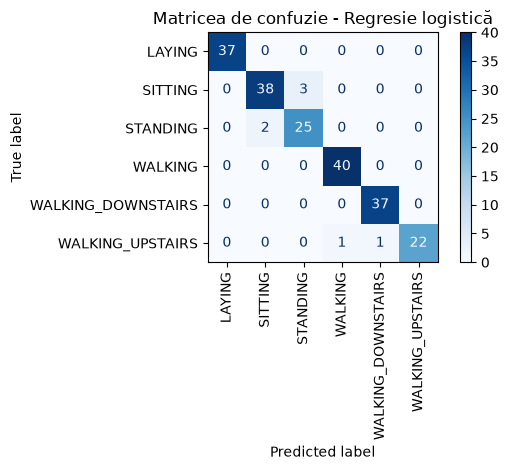

In [8]:
logistic_model = LogisticRegressionCV(
    cv=3,
    max_iter=1500,
    scoring='accuracy',
    n_jobs=1,
    random_state=42,
    l1_ratios=(0.0,),
    use_legacy_attributes=True
)
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

print('Acuratețe regresie logistică:', accuracy_score(y_test, logistic_predictions))
print(classification_report(y_test, logistic_predictions, target_names=label_encoder.classes_, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap='Blues',
    values_format='d',
    xticks_rotation='vertical'
)
plt.title('Matricea de confuzie - Regresie logistică')
plt.tight_layout()
plt.show()


Verificați erorile și matricea de confuzie pentru modelul de regresie logistică.

Acuratețe model stivuit: 0.970873786407767
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00        37
           SITTING       0.95      0.95      0.95        41
          STANDING       0.93      0.93      0.93        27
           WALKING       0.98      1.00      0.99        40
WALKING_DOWNSTAIRS       0.97      1.00      0.99        37
  WALKING_UPSTAIRS       1.00      0.92      0.96        24

          accuracy                           0.97       206
         macro avg       0.97      0.97      0.97       206
      weighted avg       0.97      0.97      0.97       206

Acuratețile modelelor: {'Gradient Boosting': 0.9514563106796117, 'AdaBoost': 0.6699029126213593, 'Regresie logistică': 0.9660194174757282, 'Voting Classifier': 0.970873786407767}
Cel mai bun model: Voting Classifier
Acuratețe cel mai bun model: 0.970873786407767


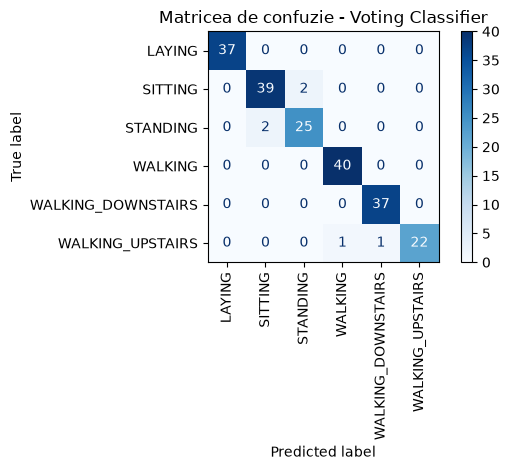

In [9]:
voting_model = VotingClassifier(
    estimators=[('logistic', logistic_model), ('gradient_boosting', best_gb)],
    voting='soft',
    n_jobs=1
)
voting_model.fit(X_train, y_train)
voting_predictions = voting_model.predict(X_test)

print('Acuratețe model stivuit:', accuracy_score(y_test, voting_predictions))
print(classification_report(y_test, voting_predictions, target_names=label_encoder.classes_, zero_division=0))

model_accuracies = {
    'Gradient Boosting': accuracy_score(y_test, gb_predictions),
    'AdaBoost': accuracy_score(y_test, ada_predictions),
    'Regresie logistică': accuracy_score(y_test, logistic_predictions),
    'Voting Classifier': accuracy_score(y_test, voting_predictions)
}

best_model_name = max(model_accuracies, key=model_accuracies.get)
best_predictions = {
    'Gradient Boosting': gb_predictions,
    'AdaBoost': ada_predictions,
    'Regresie logistică': logistic_predictions,
    'Voting Classifier': voting_predictions
}[best_model_name]

print('Acuratețile modelelor:', model_accuracies)
print('Cel mai bun model:', best_model_name)
print('Acuratețe cel mai bun model:', model_accuracies[best_model_name])

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap='Blues',
    values_format='d',
    xticks_rotation='vertical'
)
plt.title('Matricea de confuzie - ' + best_model_name)
plt.tight_layout()
plt.show()


Și acum modelul stivuit.